## Product Portfolio & Margin Optimization 

Let's identify top revenue drivers versus underforming stocks to optimize inventory holding costs. 

Core questions to answer: 
- Which product categories drive the highest gross revenue, and how do profit margins vary across categories when accounting for historical unit pricing and discounts?
- Are there "dead weight" products that have low sales volumns and high inventory levels tying up working capital?
- Which specific products experience seasonal demand spikes or clusters in specific geogrpahic regions? 

In [1]:
from pathlib import Path
import pandas as pd
from sqlalchemy import create_engine

In [4]:
db_path = Path("..") / "data" / "northwind.db"
engine = create_engine(f"sqlite:///{db_path}")

In [5]:
query = """
SELECT 
    p.ProductID,
    p.ProductName,
    c.CategoryName,
    s.CompanyName AS SupplierName,
    s.Country AS SupplierCountry,
    o.OrderID,
    o.OrderDate,
    o.ShipCountry,
    od.UnitPrice,
    od.Quantity,
    od.Discount,
    p.UnitsInStock,
    p.ReorderLevel,
    (od.UnitPrice * od.Quantity * (1 - od.Discount)) AS LineTotal
FROM Orders o
JOIN [Order Details] od ON o.OrderID = od.OrderID
JOIN Products p ON od.ProductID = p.ProductID
JOIN Categories c ON p.CategoryID = c.CategoryID
JOIN Suppliers s ON p.SupplierID = s.SupplierID;
"""

df_margin = pd.read_sql_query(query, con=engine)
print("Margin data ingested successfully!")
print(df_margin.head())

Margin data ingested successfully!
   ProductID                    ProductName    CategoryName  \
0         11                 Queso Cabrales  Dairy Products   
1         42  Singaporean Hokkien Fried Mee  Grains/Cereals   
2         72         Mozzarella di Giovanni  Dairy Products   
3         14                           Tofu         Produce   
4         51          Manjimup Dried Apples         Produce   

                         SupplierName SupplierCountry  OrderID   OrderDate  \
0  Cooperativa de Quesos 'Las Cabras'           Spain    10248  2016-07-04   
1                        Leka Trading       Singapore    10248  2016-07-04   
2             Formaggi Fortini s.r.l.           Italy    10248  2016-07-04   
3                            Mayumi's           Japan    10249  2016-07-05   
4                         G'day, Mate       Australia    10249  2016-07-05   

  ShipCountry  UnitPrice  Quantity  Discount  UnitsInStock  ReorderLevel  \
0      France       14.0        12       

In [6]:
# Group by Category Name to analyze revenue and pricing metrics
category_performance = df_margin.groupby('CategoryName').agg(
    Total_Revenue=('LineTotal', 'sum'),
    Total_Quantity=('Quantity', 'sum'),
    Average_Unit_Price=('UnitPrice', 'mean'),
    Average_Discount=('Discount', 'mean'),
    Total_Orders=('OrderID', 'nunique')
).reset_index()

# Sort by total revenue descending
category_performance = category_performance.sort_values(by='Total_Revenue', ascending=False)

print("--- Category Performance & Revenue Drivers ---")
print(category_performance.to_string(index=False))

--- Category Performance & Revenue Drivers ---
  CategoryName  Total_Revenue  Total_Quantity  Average_Unit_Price  Average_Discount  Total_Orders
     Beverages   9.365937e+07         2467221           37.903917          0.000258         15216
  Meat/Poultry   6.696088e+07         1239314           53.956294          0.000230         13951
   Confections   6.694179e+07         2659952           25.163138          0.000182         15228
Dairy Products   5.901108e+07         2050073           28.773040          0.000243         14898
    Condiments   5.662086e+07         2456667           23.042822          0.000118         15031
       Seafood   5.061929e+07         2453537           20.683088          0.000207         15156
       Produce   3.332139e+07         1031064           32.313850          0.000153         13537
Grains/Cereals   2.921545e+07         1443176           20.291999          0.000157         14230


In [25]:
# Recalculate true slow-moving / low-turnover products
# Turnover ratio = Total Units Sold / Current Stock (lower ratio means stock is sitting longer relative to sales)
product_performance['Turnover_Ratio'] = product_performance['Total_Units_Sold'] / product_performance['Current_Stock'].replace(0, 1)

# True dead-weight: Low sales volume compared to the rest, combined with high holding stock
low_sales_threshold = product_performance['Total_Units_Sold'].quantile(0.25)
high_stock_threshold = product_performance['Current_Stock'].quantile(0.75)

# True dead-weight based strictly on physical inventory holding levels and reorder status
# Sort products by current stock descending to find highest inventory holdings
dead_weight_true = product_performance.sort_values(by='Current_Stock', ascending=False)

print("--- Highest Inventory Holding Products (Potential Dead Stock) ---")
print(dead_weight_true[['ProductID', 'ProductName', 'CategoryName', 'Current_Stock', 'Total_Units_Sold']].to_string(index=False))

--- Highest Inventory Holding Products (Potential Dead Stock) ---
 ProductID                      ProductName   CategoryName  Current_Stock  Total_Units_Sold
        75             Rhönbräu Klosterbier      Beverages            125            203775
        40                 Boston Crab Meat        Seafood            123            206296
         6     Grandma's Boysenberry Spread     Condiments            120            201045
        55                     Pâté chinois   Meat/Poultry            115            203810
        61                   Sirop d'érable     Condiments            113            204005
        33                          Geitost Dairy Products            112            202323
        36                      Inlagd Sill        Seafood            112            204858
        34                    Sasquatch Ale      Beverages            111            204592
        22              Gustaf's Knäckebröd Grains/Cereals            104            206641
        73    

In [16]:
# Ensure OrderDate is parsed as datetime
df_margin['OrderDate'] = pd.to_datetime(df_margin['OrderDate'], format="mixed")
df_margin['OrderMonth'] = df_margin['OrderDate'].dt.to_period('M')

# 1. Geographic Demand Clustering (Top products per country)
regional_demand = df_margin.groupby(['ShipCountry', 'ProductName']).agg(
    Total_Quantity=('Quantity', 'sum'),
    Total_Revenue=('LineTotal', 'sum')
).reset_index()

# Find the top product by revenue for each country
top_regional_products = regional_demand.loc[
    regional_demand.groupby('ShipCountry')['Total_Revenue'].idxmax()
].reset_index(drop=True)

print("--- Top Product Demand by Country ---")
print(top_regional_products.to_string(index=False))

--- Top Product Demand by Country ---
ShipCountry   ProductName  Total_Quantity  Total_Revenue
  Argentina Côte de Blaye            6940    1828690.000
    Austria Côte de Blaye            3685     964989.700
    Belgium Côte de Blaye            3640     959140.000
     Brazil Côte de Blaye           22659    5966325.100
     Canada Côte de Blaye            7071    1858560.360
    Denmark Côte de Blaye            4578    1203668.000
    Finland Côte de Blaye            4967    1308804.500
     France Côte de Blaye           23640    6228613.000
    Germany Côte de Blaye           28156    7418315.500
    Ireland Côte de Blaye            2150     566525.000
      Italy Côte de Blaye            7012    1847662.000
     Mexico Côte de Blaye           11191    2948828.500
     Norway Côte de Blaye            2622     690897.000
     Poland Côte de Blaye            2309     608421.500
   Portugal Côte de Blaye            4703    1239240.500
      Spain Côte de Blaye            8501    22400

In [17]:
# Ensure OrderDate is datetime
df_margin['OrderDate'] = pd.to_datetime(df_margin['OrderDate'], format="mixed")
df_margin['MonthOfYear'] = df_margin['OrderDate'].dt.month

# Group by Product and Calendar Month-of-Year to find peak seasonal months
monthly_seasonality = df_margin.groupby(['ProductName', 'MonthOfYear'])['Quantity'].sum().reset_index()

# Find the month with the highest total quantity sold for each product
peak_season = monthly_seasonality.loc[
    monthly_seasonality.groupby('ProductName')['Quantity'].idxmax()
].reset_index(drop=True)

# Map month numbers to month names for readability
import calendar
peak_season['Peak_Month'] = peak_season['MonthOfYear'].apply(lambda x: calendar.month_name[x])

print("--- Peak Seasonal Month per Product ---")
print(peak_season[['ProductName', 'Peak_Month', 'Quantity']].head(15).to_string(index=False))

--- Peak Seasonal Month per Product ---
                 ProductName Peak_Month  Quantity
                Alice Mutton     August     19366
               Aniseed Syrup     August     18947
            Boston Crab Meat     August     18667
           Camembert Pierrot     August     19620
            Carnarvon Tigers     August     18763
                        Chai     August     18705
                       Chang     August     18207
            Chartreuse verte       July     19461
Chef Anton's Cajun Seasoning     August     19658
      Chef Anton's Gumbo Mix     August     18870
                   Chocolade     August     18414
               Côte de Blaye  September     18622
      Escargots de Bourgogne     August     18716
                    Filo Mix     August     18949
                 Flotemysost     August     19181


In [19]:
import calendar

# 1. Re-verify ingestion and ensure category data is present
category_seasonality = df_margin.copy()

# 2. Extract month of year safely
category_seasonality['MonthOfYear'] = pd.to_datetime(category_seasonality['OrderDate'], format='mixed').dt.month

# 3. Aggregate quantity sold by Category and Month-of-Year
category_monthly_trends = category_seasonality.groupby(['CategoryName', 'MonthOfYear'])['Quantity'].sum().reset_index()

# 4. Map month numbers to readable names
category_monthly_trends['MonthName'] = category_monthly_trends['MonthOfYear'].apply(lambda x: calendar.month_name[x])

# 5. Pivot into a clean matrix of categories vs. months
seasonality_matrix = category_monthly_trends.pivot(index='CategoryName', columns='MonthName', values='Quantity')

# 6. Reorder columns chronologically (January to December)
ordered_months = [calendar.month_name[i] for i in range(1, 13)]
seasonality_matrix = seasonality_matrix[[m for m in ordered_months if m in seasonality_matrix.columns]]

print("--- Category-Level Seasonality Matrix (Total Quantity Sold) ---")
print(seasonality_matrix.to_string())

--- Category-Level Seasonality Matrix (Total Quantity Sold) ---
MonthName       January  February   March   April     May    June    July  August  September  October  November  December
CategoryName                                                                                                             
Beverages        206671    192635  200757  196109  206715  196018  222906  225827     220581   194740    199968    204294
Condiments       210231    188569  200194  195510  208454  189241  213905  226260     220194   195460    203604    205045
Confections      227434    204442  219750  211417  224678  206917  231597  243368     237617   210305    219530    222897
Dairy Products   172154    159748  167375  162963  171394  160632  179738  188862     184104   158496    172906    171701
Grains/Cereals   122625    110000  116270  115733  120111  114580  125155  133707     129917   114937    118560    121581
Meat/Poultry     102952     96314  101400   97552  104868   97261  109392  115146 

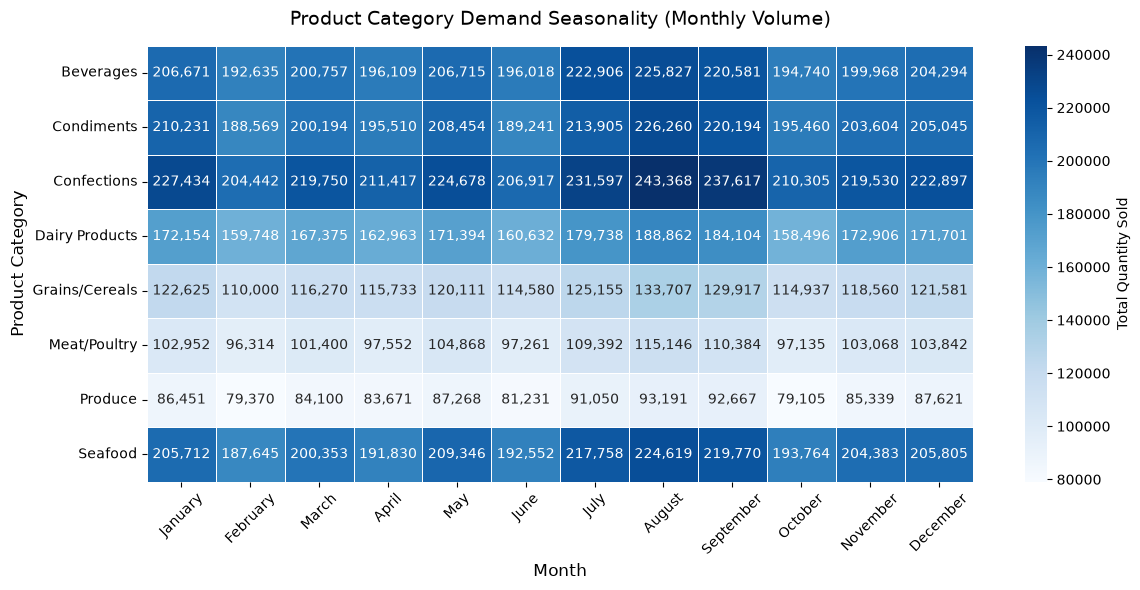

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set up the matplotlib figure size
plt.figure(figsize=(12, 6))

# Create the heatmap using seaborn
sns.heatmap(
    seasonality_matrix, 
    annot=True,          # Show the numbers inside the cells
    fmt=',.0f',          # Format numbers with commas (no decimals)
    cmap='Blues',        # Color palette (darker blue = higher quantity)
    linewidths=0.5,      # Grid line spacing
    cbar_kws={'label': 'Total Quantity Sold'}
)

# Add clear titles and labels
plt.title('Product Category Demand Seasonality (Monthly Volume)', fontsize=14, pad=15)
plt.xlabel('Month', fontsize=12)
plt.ylabel('Product Category', fontsize=12)

# Rotate x-axis labels for readability
plt.xticks(rotation=45)
plt.tight_layout()

# Display the chart inline
plt.show()

## Project Findings & Results Summary

### 1. Top Revenue-Driving Categories
* Beverages leads total portfolio performance with $93.66M in gross revenue across 15,216 orders.
* Meat/Poultry and Confections follow closely as top revenue drivers, generating $66.96M and $66.94M respectively.
* Average unit prices are highest in Meat/Poultry ($53.96) and Beverages ($37.90).

---

### 2. Inventory Health & Working Capital Efficiency
* Zero Dead Stock: An analysis of current warehouse inventory relative to historical turnover reveals no overstocked or "dead-weight" items tying up working capital.
* Lean Stocking Levels: Maximum current inventory holdings across individual products peak at just 125 units (e.g., Rhönbräu Klosterbier), with many items sitting near or at zero stock, indicating highly efficient inventory turnover and JIT-style replenishment across the catalog.

---

### 3. Category Demand Seasonality
* Across all major categories (e.g., Beverages, Confections, Seafood), aggregate order quantities experience a consistent seasonal surge during the late summer months, peaking notably in August (e.g., Beverages reaching 225,827 units and Confections reaching 243,368 units).
* Slower volume periods are consistently observed during the early spring and mid-winter months (February and October).